In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import files

In [ ]:
df = pd.read_csv('Project1WeatherDataset.csv')

In [ ]:
print("=== DATASET OVERVIEW ===")
print("Shape (Rows, Columns):", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

=== DATASET OVERVIEW ===
Shape (Rows, Columns): (8784, 8)

First 5 Rows:


,Date/Time,Temp_C,Dew Point Temp_C,Rel Hum_%,Wind Speed_km/h,Visibility_km,Press_kPa,Weather
0,1/1/2012 0:00,-1.8,-3.9,86,4,8.0,101.24,Fog
1,1/1/2012 1:00,-1.8,-3.7,87,4,8.0,101.24,Fog
2,1/1/2012 2:00,-1.8,-3.4,89,7,4.0,101.26,"Freezing Drizzle,Fog"
3,1/1/2012 3:00,-1.5,-3.2,88,6,4.0,101.27,"Freezing Drizzle,Fog"
4,1/1/2012 4:00,-1.5,-3.3,88,7,4.8,101.23,Fog


In [ ]:
# Pandas operations

print("\n=== PANDAS OPERATIONS ===")
df['Date/Time'] = pd.to_datetime(df['Date/Time'])
print("\nTop 5 Weather Conditions:")
print(df['Weather'].value_counts().head(5))

snow_clear = df[(df['Weather'] == 'Snow') & (df['Visibility_km'] > 8)]
print(f"\nNumber of records with Snow and Visibility > 8km: {len(snow_clear)}")

monthly_avg = (
    df.groupby(df['Date/Time'].dt.month_name())[
        ['Temp_C', 'Rel Hum_%', 'Wind Speed_km/h']
    ]
    .mean()
    .round(2)
)
print("\nMonthly Averages:")
display(monthly_avg.head())


=== PANDAS OPERATIONS ===

Top 5 Weather Conditions:
Weather
Mainly Clear     2106
Mostly Cloudy    2069
Cloudy           1728
Clear            1326
Snow              390
Name: count, dtype: int64

Number of records with Snow and Visibility > 8km: 204

Monthly Averages:


,Temp_C,Rel Hum_%,Wind Speed_km/h
Date/Time,,,
April,7.01,56.15,17.37
August,22.28,67.94,13.93
December,-3.31,81.30,17.61
February,-4.22,68.96,14.84
January,-7.37,68.38,18.11


In [ ]:
# Numpy Operations

print("\n=== NUMPY OPERATIONS ===")
temp_array = df['Temp_C'].to_numpy()
humidity_array = df['Rel Hum_%'].to_numpy()

mean_temp = np.mean(temp_array)
median_temp = np.median(temp_array)
std_temp = np.std(temp_array)
p90_humidity = np.percentile(humidity_array, 90)

corr_matrix = np.corrcoef(temp_array, humidity_array)

print(f"Mean Temperature: {mean_temp:.2f} °C")
print(f"Median Temperature: {median_temp:.2f} °C")
print(f"Standard Deviation: {std_temp:.2f}")
print(f"90th Percentile Humidity: {p90_humidity:.2f} %")
print(f"Correlation between Temp and Humidity: {corr_matrix[0, 1]:.2f}")


=== NUMPY OPERATIONS ===
Mean Temperature: 8.80 °C
Median Temperature: 9.30 °C
Standard Deviation: 11.69
90th Percentile Humidity: 89.00 %
Correlation between Temp and Humidity: -0.22


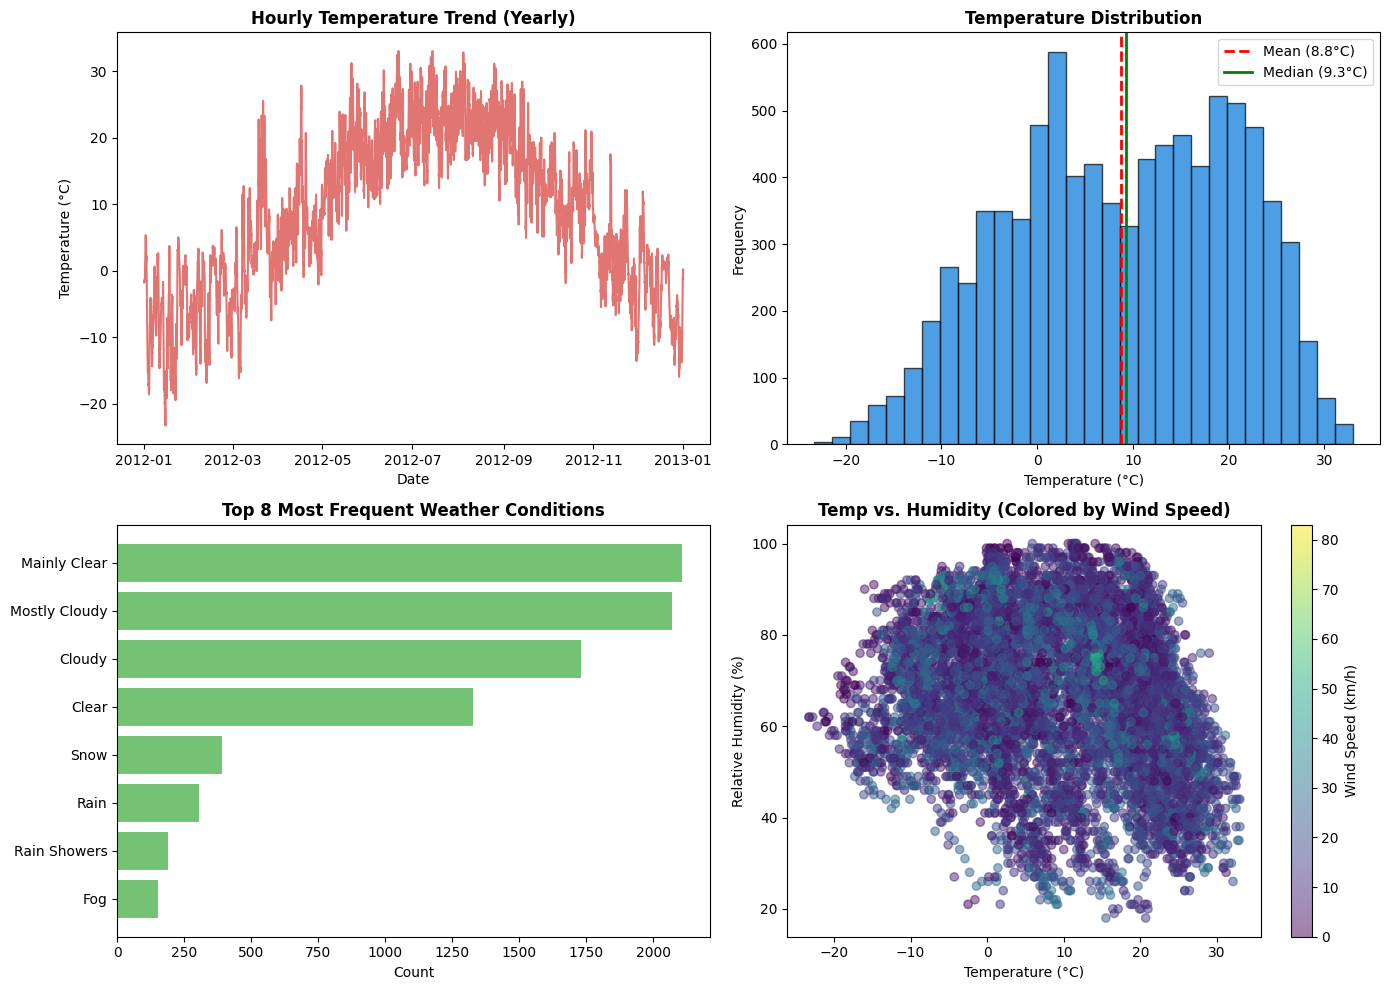

In [ ]:
# Matplotlib Operations

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(df['Date/Time'], df['Temp_C'], color='#d9534f', alpha=0.8)
axes[0, 0].set_title(
    'Hourly Temperature Trend (Yearly)', fontsize=12, fontweight='bold'
)
axes[0, 0].set_xlabel('Date')
axes[0, 0].set_ylabel('Temperature (°C)')

axes[0, 1].hist(
    temp_array, bins=30, color='#0275d8', edgecolor='black', alpha=0.7
)
axes[0, 1].axvline(
    mean_temp,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Mean ({mean_temp:.1f}°C)',
)
axes[0, 1].axvline(
    median_temp,
    color='green',
    linestyle='-',
    linewidth=2,
    label=f'Median ({median_temp:.1f}°C)',
)
axes[0, 1].set_title(
    'Temperature Distribution', fontsize=12, fontweight='bold'
)
axes[0, 1].set_xlabel('Temperature (°C)')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].legend()

top_weather = df['Weather'].value_counts().head(8)
axes[1, 0].barh(
    top_weather.index, top_weather.values, color='#5cb85c', alpha=0.85
)
axes[1, 0].set_title(
    'Top 8 Most Frequent Weather Conditions', fontsize=12, fontweight='bold'
)
axes[1, 0].set_xlabel('Count')
axes[1, 0].invert_yaxis()

scatter = axes[1, 1].scatter(
    df['Temp_C'],
    df['Rel Hum_%'],
    c=df['Wind Speed_km/h'],
    cmap='viridis',
    alpha=0.5,
)
axes[1, 1].set_title(
    'Temp vs. Humidity (Colored by Wind Speed)', fontsize=12, fontweight='bold'
)
axes[1, 1].set_xlabel('Temperature (°C)')
axes[1, 1].set_ylabel('Relative Humidity (%)')
cbar = fig.colorbar(scatter, ax=axes[1, 1])
cbar.set_label('Wind Speed (km/h)')

plt.tight_layout()
plt.show()